# Setup

In [1]:
!pip install -q datasets transformers accelerate pandas matplotlib

In [2]:
import random, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

random.seed(42); np.random.seed(42); torch.manual_seed(42)
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"

# 1. Problem Definition

**What we build:** an *Answer-or-Abstain* document assistant.

| | |
|---|---|
| **User** | Students, researchers, support teams who need answers from a document |
| **Input** | A paragraph + a question |
| **Output** | Answer, the sentence that proves it, a confidence score – or **"not in the document"** |
| **Problem** | LLMs often *make up* an answer when the paragraph doesn't contain one |

**Output format (JSON):**
```json
{"answerable": true, "answer": "1876", "evidence": "Bell patented the telephone in 1876.", "confidence": 0.82}
```

**Why an LLM?** It can follow instructions, write JSON, quote evidence and say "not found" – all from a prompt, with **no training** on our side.

# 2. Dataset Understanding
**SQuAD v2** (from Hugging Face). Each row = one Wikipedia paragraph + one question + the correct answer.
Unanswerable questions have an **empty answer list** – the model should say "not in the document" for them.

In [3]:
squad = load_dataset("rajpurkar/squad_v2")
train = squad["train"].to_pandas()
val   = squad["validation"].to_pandas()

for d in (train, val):
    d["gold_answers"]   = d["answers"].map(lambda a: list(a["text"]))
    d["answer_starts"]  = d["answers"].map(lambda a: [int(x) for x in a["answer_start"]])
    d["is_answerable"]  = d["gold_answers"].map(len) > 0
    d.drop(columns="answers", inplace=True)

print("train rows     :", len(train), "| unanswerable:", (~train.is_answerable).sum())
print("validation rows:", len(val),   "| unanswerable:", (~val.is_answerable).sum())
print("columns:", list(val.columns))

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

train rows     : 130319 | unanswerable: 43498
validation rows: 11873 | unanswerable: 5945
columns: ['id', 'title', 'context', 'question', 'gold_answers', 'answer_starts', 'is_answerable']


### 2.1 Build the evaluation set (200 questions, frozen)

In [ ]:
import os; os.makedirs("data", exist_ok=True)

# The eval set is FROZEN: if the shared file exists, load it instead of rebuilding.
if os.path.exists("data/eval_set.jsonl"):
    eval_set = pd.read_json("data/eval_set.jsonl", lines=True)
    print("Loaded the shared, frozen eval set")
else:
    # up to 3 questions per article first (so many articles are used), then pick 100 of each type
    def pick(df, n):
        return df.groupby("title").head(3).sample(n, random_state=42)

    eval_set = pd.concat([pick(val[val.is_answerable], 100), pick(val[~val.is_answerable], 100)])
    eval_set = eval_set.sample(frac=1, random_state=42).reset_index(drop=True)   # shuffle
    eval_set.to_json("data/eval_set.jsonl", orient="records", lines=True)
    print("Built and saved a new eval set")

print("rows:", len(eval_set), "| answerable:", eval_set.is_answerable.sum(),
      "| unanswerable:", (~eval_set.is_answerable).sum(), "| articles:", eval_set.title.nunique())

**In simple words:** we pick 100 answerable + 100 unanswerable questions from the *validation* part and save them in `data/eval_set.jsonl`.
**Everybody in the team uses this same file** – so results can be compared. Never re-create it after sharing.

### 2.2 Few-shot examples (from the *train* part, so no overlap with the test)

In [ ]:
import re

# evidence = the sentence that contains the answer, found from the answer's character position
def find_evidence(row):
    if not row.is_answerable: return ""
    start = row.answer_starts[0]
    bounds = [0] + [m.end() for m in re.finditer(r'[.!?]\s+', row.context)] + [len(row.context)]
    for a, b in zip(bounds, bounds[1:]):
        if a <= start < b:
            return row.context[a:b].strip()
    return ""

if os.path.exists("data/fewshot_pool.jsonl"):
    fewshot = pd.read_json("data/fewshot_pool.jsonl", lines=True)
    print("Loaded the shared few-shot pool")
else:
    short = train[train.context.str.len() < 600]
    ans   = short[short.is_answerable].sample(3, random_state=42).copy()
    unans = short[~short.is_answerable].sample(1, random_state=42).copy()
    fewshot = pd.concat([ans, unans]).reset_index(drop=True)
    fewshot["evidence"] = fewshot.apply(find_evidence, axis=1)
    fewshot.to_json("data/fewshot_pool.jsonl", orient="records", lines=True)
    print("Built and saved a new few-shot pool")

# Sanity checks
assert not set(fewshot.id) & set(eval_set.id)                       # no shared questions
assert not set(fewshot.title) & set(eval_set.title)                 # stronger: no shared articles
for r in fewshot.itertuples():                                      # evidence must contain the answer
    if r.is_answerable:
        assert r.gold_answers[0] in r.evidence, r.question
        print("OK |", r.gold_answers[0], "|", r.evidence[:90])
print(fewshot[["question", "gold_answers", "is_answerable"]])

### 2.3 Dataset statistics

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

is_answerable
answerable      100
unanswerable    100
Name: count, dtype: int64 

       context_tokens  question_tokens
count           200.0            200.0
mean            177.6             11.5
std              74.2              3.8
min              82.0              6.0
25%             135.0              9.0
50%             168.0             10.0
75%             206.0             14.0
max             502.0             23.0


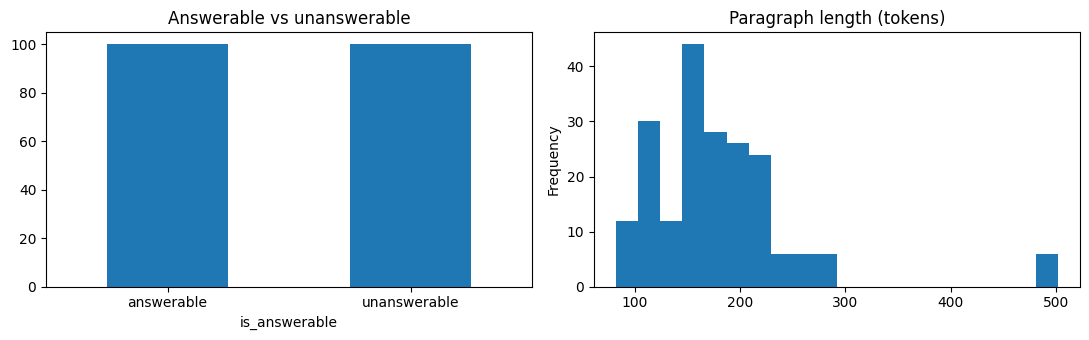

In [6]:
tok = AutoTokenizer.from_pretrained(MODEL)
count = lambda text: len(tok(text, add_special_tokens=False)["input_ids"])

eval_set["context_tokens"]  = eval_set.context.map(count)
eval_set["question_tokens"] = eval_set.question.map(count)

print(eval_set.is_answerable.map({True: "answerable", False: "unanswerable"}).value_counts(), "\n")
stats = eval_set[["context_tokens", "question_tokens"]].describe().round(1)
print(stats)
stats.to_csv("dataset_stats.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
eval_set.is_answerable.map({True: "answerable", False: "unanswerable"}).value_counts().plot.bar(ax=ax[0], title="Answerable vs unanswerable", rot=0)
eval_set.context_tokens.plot.hist(bins=20, ax=ax[1], title="Paragraph length (tokens)")
plt.tight_layout(); plt.savefig("fig_dataset_stats.png", dpi=150); plt.show()

A *token* is a piece of a word (what the model actually reads). The table shows how long paragraphs and questions are in tokens.
A typical paragraph is only a few hundred tokens, so even 4 paragraphs together (for the context-noise test) fit easily.

### 2.4 Three sample records

In [7]:
samples = pd.concat([eval_set[eval_set.is_answerable].head(2), eval_set[~eval_set.is_answerable].head(1)])
for _, r in samples.iterrows():
    print("-" * 80)
    print("Answerable:", r.is_answerable)
    print("Context   :", r.context[:300], "...")
    print("Question  :", r.question)
    print("Gold      :", r.gold_answers if r.gold_answers else "[]  -> model must say 'not in the document'")
samples[["id", "question", "gold_answers", "is_answerable"]].to_csv("sample_records.csv", index=False)

--------------------------------------------------------------------------------
Answerable: True
Context   : The Yuan dynasty (Chinese: 元朝; pinyin: Yuán Cháo), officially the Great Yuan (Chinese: 大元; pinyin: Dà Yuán; Mongolian: Yehe Yuan Ulus[a]), was the empire or ruling dynasty of China established by Kublai Khan, leader of the Mongolian Borjigin clan. Although the Mongols had ruled territories including ...
Question  : Who started the Yuan dynasty?
Gold      : ['Kublai Khan', 'Kublai Khan', 'Kublai Khan']
--------------------------------------------------------------------------------
Answerable: True
Context   : Computational complexity theory is a branch of the theory of computation in theoretical computer science that focuses on classifying computational problems according to their inherent difficulty, and relating those classes to each other. A computational problem is understood to be a task that is in  ...
Question  : By what main attribute are computational problems classifi

### 2.5 Preprocessing record (for the report)
1. Load SQuAD v2 (`rajpurkar/squad_v2`) with the Hugging Face `datasets` library.
2. Convert to a table; `is_answerable = answer list is not empty`.
3. Evaluation set: 100 answerable + 100 unanswerable from the **validation** split, max 3 per article first, `random_state=42`, saved as `data/eval_set.jsonl`.
4. Few-shot pool: 3 answerable + 1 unanswerable short examples from the **train** split, saved as `data/fewshot_pool.jsonl`; checked that none are in the eval set. No leakage is possible: SQuAD's train and validation splits use **different Wikipedia articles**, so no paragraph appears in both (the notebook also asserts no shared article titles).
5. No text cleaning – the model reads the original text.


### Why we made these choices
| Choice | Reason |
|---|---|
| **SQuAD v2 from Hugging Face** (not the Kaggle copy) | Kaggle copies are usually v1.1, where every question has an answer. v2 adds unanswerable questions, which we need to test whether the model abstains instead of guessing. |
| **Validation split for the eval set** | Validation questions have several human answers, so scoring is fairer. The model is never trained on them. |
| **100 answerable + 100 unanswerable** | Balanced, so answering and abstaining are measured equally. 200 questions is small enough to run many experiments on a free T4 GPU. With 100 per type, one question is worth 1 percentage point, so differences of only a few points may be chance and should not be over-interpreted. |
| **Up to 3 questions per article first** | Stops a few articles from dominating the test, so the eval set covers many topics (all 35 validation articles). |
| **Few-shot examples from the train split** | Train and validation are separate, so no test question can appear inside a prompt (no data leakage). |
| **Short paragraphs (under 600 characters) for few-shot** | Keeps prompts short and the examples easy to read. |
| **3 answerable + 1 unanswerable few-shot example** | The unanswerable example shows the model that "not in the document" is an allowed answer. |
| **No text cleaning** | The model reads the original text, so answers and evidence sentences can be matched exactly against the paragraph later. |
| **Seed 42 everywhere** | Anyone re-running the notebook gets the same eval set and results. |
| **Qwen2.5-1.5B-Instruct** | Free, fits a T4 GPU (about 3 GB), decoder-only, and good at following instructions and writing JSON. |
| **Shortest paragraph for the architecture demo** | Easy to read in the printouts. |

### 2.6 Dataset challenges and limitations
- **Adversarial unanswerable questions:** crowd workers wrote them to *look* answerable — they reuse words from the paragraph — so a model that matches keywords will invent answers.
- **Multiple gold answers:** e.g. "inherent difficulty" / "their inherent difficulty". Scoring must take the best match, which is why we use F1 alongside Exact Match.
- **Single domain:** only Wikipedia; results may not transfer to company documents or chat text.
- **Small article pool:** the validation split has only 35 articles in total; our eval set uses all 35.
- **Possible data contamination:** the model may have seen Wikipedia or SQuAD during pretraining, which can make scores look better than they are. We therefore compare systems on the same set rather than claim absolute accuracy.

# 3. Generative Model Analysis

| Model type | How it creates output | Strengths | Weaknesses | Fit for our QA task |
|---|---|---|---|---|
| **VAE** | Decodes a random code (latent vector) into a sample | Smooth, compressed representations; stable training; fast sampling | Text decoded from one code tends to be blurry or short; cannot read a paragraph plus a question and answer exactly | Poor |
| **GAN** | A generator tries to fool a judge (discriminator) | Very realistic images; fast one-step generation | Text is made of discrete words, so training is unstable and hard to control; no control over facts | Poor |
| **Diffusion** | Starts from noise and removes it step by step | State-of-the-art images and audio; diverse outputs | Slow (many steps); text versions are still immature; images are not needed in this project | Poor for now |
| **Autoregressive LLM** (decoder-only Transformer) | Predicts the next token again and again | Handles text natively; follows instructions from a prompt; can write JSON and call tools; gives a probability for every token, which we use as confidence | Can sound confident when wrong (hallucination); sensitive to prompt wording; long prompts cost memory | **Best** |

**Why a decoder-only LLM fits our project**
1. Our task is *text in → text out* (paragraph + question → answer).
2. The prompt alone changes its behaviour – no training needed.
3. It can write JSON, quote evidence and call a tool.
4. It gives a **probability for every word**, which we use as a real confidence score.
5. "Not in the document" is just another answer it can choose.

**In simple words:** VAEs, GANs and diffusion models are mainly for images; a language model is built to continue text, which is exactly what answering a question is.

# 4. LLM Architecture
We follow **one real question** through the model, step by step:
**text → tokens → embeddings → attention layers → next-word probabilities → repeat.**

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModelForCausalLM.from_pretrained(
    MODEL, dtype=torch.float16 if device == "cuda" else torch.float32,
    attn_implementation="eager").to(device)      # "eager" lets us look at attention weights
model.eval()
cfg = model.config
print(f"layers={cfg.num_hidden_layers}  vector size={cfg.hidden_size}  query heads={cfg.num_attention_heads}  "
      f"key/value heads={cfg.num_key_value_heads}  vocabulary={cfg.vocab_size:,}")

# the shortest answerable paragraph in our eval set -> easy to read
row = eval_set[eval_set.is_answerable].sort_values("context_tokens").iloc[0]
messages = [
    {"role": "system", "content": "Answer using ONLY the context. If the answer is not in the context, say: not in the document."},
    {"role": "user",   "content": f"Context: {row.context}\n\nQuestion: {row.question}"},
]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
print("\nQuestion:", row.question, "| Gold answer:", row.gold_answers)

**In simple words:** we load the model (1.5 billion numbers). It has 28 layers; each token is represented by a vector of 1536 numbers.

**What one layer contains (×28):** (1) causal self-attention — each token looks only at earlier tokens; (2) a feed-forward network (SwiGLU MLP) that processes each token's vector on its own. Each part is wrapped in a **residual connection** (the input is added back to the output) and **RMSNorm** normalisation, which keeps training stable across 28 stacked layers.

**Grouped-query attention:** the print-out shows 12 query heads but only 2 key/value heads — groups of 6 query heads share one key/value head. This cuts memory when the context is long (useful when we give the model several paragraphs).

### 4.1 Tokenization – text becomes numbers

In [9]:
inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(device)
ids = inputs["input_ids"][0]
print("Paragraph words:", len(row.context.split()), "| paragraph tokens:", count(row.context))
print("Whole prompt tokens:", len(ids))
print("\nFirst 15 tokens:", tok.convert_ids_to_tokens(ids[:15]))
print("First 15 ids   :", ids[:15].tolist())
print("\nRare words are split into pieces:", tok.tokenize("unanswerable"), tok.tokenize("1876"))

Paragraph words: 74 | paragraph tokens: 82
Whole prompt tokens: 134

First 15 tokens: ['<|im_start|>', 'system', 'Ċ', 'Answer', 'Ġusing', 'ĠONLY', 'Ġthe', 'Ġcontext', '.', 'ĠIf', 'Ġthe', 'Ġanswer', 'Ġis', 'Ġnot', 'Ġin']
First 15 ids   : [151644, 8948, 198, 16141, 1667, 26687, 279, 2266, 13, 1416, 279, 4226, 374, 537, 304]

Rare words are split into pieces: ['un', 'answer', 'able'] ['1', '8', '7', '6']


**In simple words:** the tokenizer cuts text into pieces and gives each piece an ID number. `Ġ` means "a space came before this piece". The model never sees letters – only these IDs.

### 4.2 Embeddings – each ID becomes a vector

In [10]:
embedding_layer = model.get_input_embeddings()
print("Embedding table shape:", tuple(embedding_layer.weight.shape), "= [vocabulary, vector size]")
with torch.no_grad():
    vectors = embedding_layer(inputs["input_ids"])
print("Our prompt as vectors:", tuple(vectors.shape), "= [1 prompt, tokens, vector size]")
print("First token's vector (first 6 numbers):", vectors[0, 0, :6].float().cpu().numpy().round(3))

Embedding table shape: (151936, 1536) = [vocabulary, vector size]
Our prompt as vectors: (1, 134, 1536) = [1 prompt, tokens, vector size]
First token's vector (first 6 numbers): [ 0.007  0.013 -0.005  0.     0.    -0.006]


**How does the model know word order?** The embedding of a token does not contain its position: the same word gets the same vector wherever it appears. Attention by itself also does not know order. Qwen2.5 solves this with **rotary position embeddings (RoPE)**: inside every attention layer, the query and key vectors are rotated by an angle that depends on the token's position. As a result, the attention score between two tokens depends on how far apart they are. In addition, a **causal mask** stops each token from looking at later tokens, which gives the left-to-right reading order.

**In simple words:** every token ID is looked up in a big table and replaced by a list of 1536 numbers. Words with similar meaning get similar numbers.

### 4.3 Transformer layers and attention

Attention shape per layer: (1, 12, 134, 134) = [1, heads, tokens, tokens]

What the LAST token looks at most (top 8):
  'Ċ'             (position 133)  weight=0.150
  'Ġnot'          (position 20)  weight=0.046
  'Ġare'          (position 119)  weight=0.044
  'Ġcomputational' (position 120)  weight=0.042
  'Ġutilizing'    (position 123)  weight=0.032
  'ĠBy'           (position 115)  weight=0.030
  'Ċ'             (position 29)  weight=0.028
  '?'             (position 127)  weight=0.028


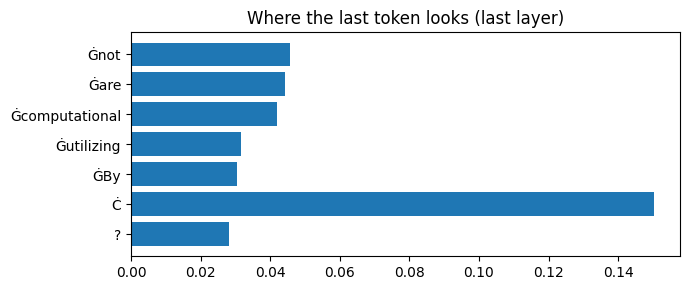

In [11]:
with torch.no_grad():
    out = model(**inputs, output_attentions=True)

tokens = tok.convert_ids_to_tokens(ids)
attn = out.attentions[-1][0].float().mean(0)[-1].cpu().numpy()     # last layer, average of heads, last token's view
top = attn.argsort()[::-1][:8]

print("Attention shape per layer:", tuple(out.attentions[0].shape), "= [1, heads, tokens, tokens]")
print("\nWhat the LAST token looks at most (top 8):")
for i in top:
    print(f"  {tokens[i]!r:15} (position {i})  weight={attn[i]:.3f}")

plt.figure(figsize=(7, 3)); plt.barh([tokens[i] for i in top][::-1], attn[top][::-1])
plt.title("Where the last token looks (last layer)"); plt.tight_layout(); plt.savefig("fig_attention.png", dpi=150); plt.show()

**In simple words:** *Attention* lets each token look back at the other tokens and decide which ones matter. The model reads left to right, never at future words.
Here we see which earlier tokens the final position pays most attention to, just before it writes the answer.

The top weight on the newline token `Ċ` is normal: models often "park" attention on special or formatting tokens (an **attention sink**). The content tokens — "computational", "utilizing", "By" from the question and paragraph — come next.

### 4.4 Language-modelling head – probability of every possible next word

In [12]:
logits = out.logits[0, -1].float()                 # one score for every word in the vocabulary
probs  = torch.softmax(logits, dim=-1)             # scores -> probabilities (sum = 1)
best   = torch.topk(probs, 5)

print("Top 5 candidates for the FIRST answer token:")
for p, i in zip(best.values, best.indices):
    print(f"  {tok.decode([int(i)])!r:15} probability = {float(p):.3f}")

Top 5 candidates for the FIRST answer token:
  'By'            probability = 0.448
  'Comput'        probability = 0.234
  'The'           probability = 0.136
  'A'             probability = 0.096
  'In'            probability = 0.029


**In simple words:** at the end, the model gives a score to all 151,936 possible next tokens. The top few are shown above.
These probabilities are the basis for our **confidence score** — but the 4.5 demo below shows a trap: the first token "By" had only 0.448 probability, while "inherent" (0.995) and "difficulty" (0.999) were near-certain. The model was unsure how to *phrase* the answer, not about the *fact*. So confidence should be **averaged over the answer's tokens**, not taken from the first token alone.

### 4.5 Autoregressive generation – one token at a time

In [ ]:
current = inputs["input_ids"]
stop = tok.convert_tokens_to_ids("<|im_end|>")
answer_ids = []

for step in range(20):                                         # max 20 tokens for this demo
    with torch.no_grad():
        probs = torch.softmax(model(input_ids=current).logits[0, -1].float(), dim=-1)
    next_id = int(probs.argmax())                              # greedy = pick the most likely token
    print(f"step {step}: {tok.decode([next_id])!r:15} probability = {float(probs[next_id]):.3f}")
    if next_id == stop: break
    answer_ids.append(next_id)
    current = torch.cat([current, torch.tensor([[next_id]], device=device)], dim=1)   # add it and repeat

print("\nGenerated answer:", tok.decode(answer_ids).strip(), "| Gold:", row.gold_answers)

# same thing with the library function
lib = model.generate(**inputs, max_new_tokens=20, do_sample=False, repetition_penalty=1.0)   # switch off Qwen's hidden 1.1 penalty
print("model.generate  :", tok.decode(lib[0, len(ids):], skip_special_tokens=True).strip())

**In simple words:** the model predicts one token → adds it to the text → predicts the next → … until it writes the end marker.
`model.generate()` does exactly this loop (just faster, by remembering earlier work).
Because each token is chosen from probabilities, one wrong early token can lead to a confident but wrong answer – that is hallucination, and the rest of our project measures and controls it.

**Link to evaluation:** the model answered "By their inherent difficulty." while the gold answer is "their inherent difficulty". Exact Match = 0, but F1 ≈ 0.86 because most words overlap. This is why we report F1 alongside EM, and why our prompts ask for a short phrase copied from the context.

In [17]:
from google.colab import files

for f in [
    "data/eval_set.jsonl",
    "data/fewshot_pool.jsonl",
    "dataset_stats.csv",
    "sample_records.csv",
    "fig_dataset_stats.png",
    "fig_attention.png"
]:
    files.download(f)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>